In [1]:
import re
import html
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import (
    TfidfVectorizer,
    ENGLISH_STOP_WORDS
)
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("Tweets.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

print("\nMissing values in selected columns:")
display(df[["text", "airline_sentiment"]].isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (14640, 15)

Column names:
['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone']


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)



Missing values in selected columns:


text                 0
airline_sentiment    0
dtype: int64


Duplicate rows: 36


In [3]:
required_columns = ["text", "airline_sentiment"]

missing_columns = set(required_columns) - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df = df[required_columns].copy()

# Remove rows without text or sentiment labels
df = df.dropna(subset=required_columns)

# Convert to string and trim whitespace
df["text"] = df["text"].astype(str).str.strip()
df["airline_sentiment"] = (
    df["airline_sentiment"].astype(str).str.strip().str.lower()
)

# Keep only the three expected classes
valid_labels = ["positive", "negative", "neutral"]
df = df[df["airline_sentiment"].isin(valid_labels)]

# Remove blank text and exact duplicate text-label pairs
df = df[df["text"].ne("")]
df = df.drop_duplicates(subset=["text", "airline_sentiment"])

df = df.reset_index(drop=True)

print("Rows after preparation:", len(df))
display(df.head())

Rows after preparation: 14452


,text,airline_sentiment
0,@VirginAmerica What @dhepburn said.,neutral
1,@VirginAmerica plus you've added commercials t...,positive
2,@VirginAmerica I didn't today... Must mean I n...,neutral
3,@VirginAmerica it's really aggressive to blast...,negative
4,@VirginAmerica and it's a really big bad thing...,negative


In [4]:
sentiment_counts = (
    df["airline_sentiment"]
    .value_counts()
    .reindex(["positive", "negative", "neutral"], fill_value=0)
)

sentiment_summary = pd.DataFrame({
    "Sentiment": sentiment_counts.index,
    "Count": sentiment_counts.values,
    "Percentage": (
        sentiment_counts.values / sentiment_counts.sum() * 100
    ).round(2)
})

display(sentiment_summary)

,Sentiment,Count,Percentage
0,positive,2298,15.90
1,negative,9087,62.88
2,neutral,3067,21.22


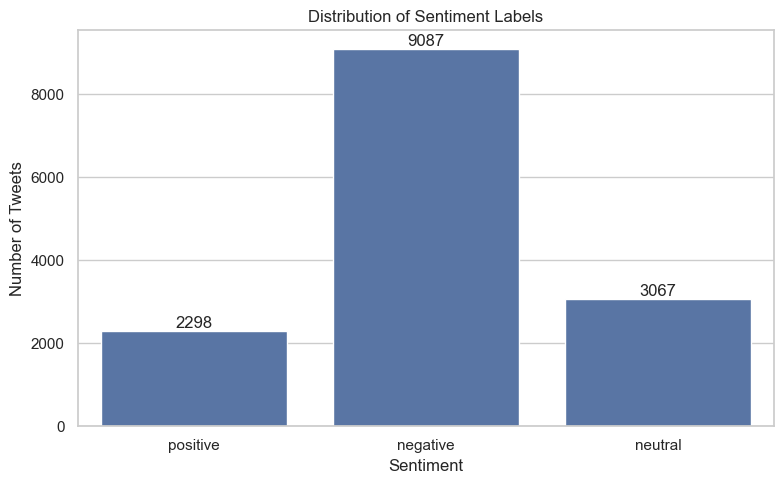

In [5]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=sentiment_summary,
    x="Sentiment",
    y="Count"
)

ax.set_title("Distribution of Sentiment Labels")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of Tweets")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sentiment_distribution.png", dpi=150)
plt.show()

In [6]:
# Keep negation words because they are important sentiment signals.
custom_stopwords = set(ENGLISH_STOP_WORDS) - {
    "not", "no", "nor", "never"
}

def preprocess_text(text):
    text = html.unescape(str(text)).lower()

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove @mentions
    text = re.sub(r"@\w+", " ", text)

    # Remove the hashtag symbol but keep the word itself
    text = re.sub(r"#(\w+)", r"\1", text)

    # Keep letters, numbers and spaces
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Tokenisation
    tokens = text.split()

    # Stopword removal, while retaining negations
    tokens = [
        token for token in tokens
        if token not in custom_stopwords
    ]

    return " ".join(tokens)


# Show examples before and after preprocessing
for sample in df["text"].head(5):
    print("Original:", sample)
    print("Cleaned: ", preprocess_text(sample))
    print("-" * 60)

df["clean_text"] = df["text"].apply(preprocess_text)

Original: @VirginAmerica What @dhepburn said.
Cleaned:  said
------------------------------------------------------------
Original: @VirginAmerica plus you've added commercials to the experience... tacky.
Cleaned:  plus ve added commercials experience tacky
------------------------------------------------------------
Original: @VirginAmerica I didn't today... Must mean I need to take another trip!
Cleaned:  didn t today mean need trip
------------------------------------------------------------
Original: @VirginAmerica it's really aggressive to blast obnoxious "entertainment" in your guests' faces &amp; they have little recourse
Cleaned:  s really aggressive blast obnoxious entertainment guests faces little recourse
------------------------------------------------------------
Original: @VirginAmerica and it's a really big bad thing about it
Cleaned:  s really big bad thing
------------------------------------------------------------


In [7]:
X = df["clean_text"]
y = df["airline_sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining distribution:")
display(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting distribution:")
display(y_test.value_counts(normalize=True).mul(100).round(2))

Training samples: 11561
Testing samples: 2891

Training distribution:


airline_sentiment
negative    62.88
neutral     21.23
positive    15.90
Name: proportion, dtype: float64


Testing distribution:


airline_sentiment
negative    62.88
neutral     21.20
positive    15.91
Name: proportion, dtype: float64

In [8]:
def make_tfidf():
    return TfidfVectorizer(
        lowercase=False,       # Already handled by preprocessing
        tokenizer=str.split,   # Tokenisation has already been performed
        preprocessor=None,
        token_pattern=None,
        ngram_range=(1, 2),    # Single words and two-word phrases
        min_df=2,
        max_features=50000,
        sublinear_tf=True
    )

models = {
    "Naive Bayes": Pipeline([
        ("tfidf", make_tfidf()),
        ("classifier", MultinomialNB(alpha=0.5))
    ]),

    "Logistic Regression": Pipeline([
        ("tfidf", make_tfidf()),
        ("classifier", LogisticRegression(
            max_iter=1500,
            class_weight=None,
            random_state=RANDOM_STATE
        ))
    ])
}

In [9]:
results = {}
predictions = {}

for model_name, model in models.items():
    print(f"\nTraining {model_name}...")

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    predictions[model_name] = y_pred

    results[model_name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision_Macro": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall_Macro": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1_Macro": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1_Weighted": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
    }

    print(f"\nClassification report: {model_name}")
    print(classification_report(
        y_test,
        y_pred,
        labels=["negative", "neutral", "positive"],
        zero_division=0
    ))


Training Naive Bayes...

Classification report: Naive Bayes
              precision    recall  f1-score   support

    negative       0.73      0.98      0.83      1818
     neutral       0.73      0.26      0.38       613
    positive       0.83      0.40      0.54       460

    accuracy                           0.73      2891
   macro avg       0.77      0.54      0.58      2891
weighted avg       0.74      0.73      0.69      2891


Training Logistic Regression...

Classification report: Logistic Regression
              precision    recall  f1-score   support

    negative       0.79      0.95      0.87      1818
     neutral       0.67      0.42      0.52       613
    positive       0.82      0.59      0.69       460

    accuracy                           0.78      2891
   macro avg       0.76      0.65      0.69      2891
weighted avg       0.77      0.78      0.76      2891



In [10]:
results_df = pd.DataFrame(results).T.sort_values(
    "F1_Macro",
    ascending=False
)

display(results_df.round(4))

results_df.to_csv(
    OUTPUT_DIR / "model_comparison.csv",
    index=True
)

,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted
Logistic Regression,0.7807,0.7605,0.6542,0.6896,0.7630
Naive Bayes,0.7343,0.7650,0.5447,0.5842,0.6908


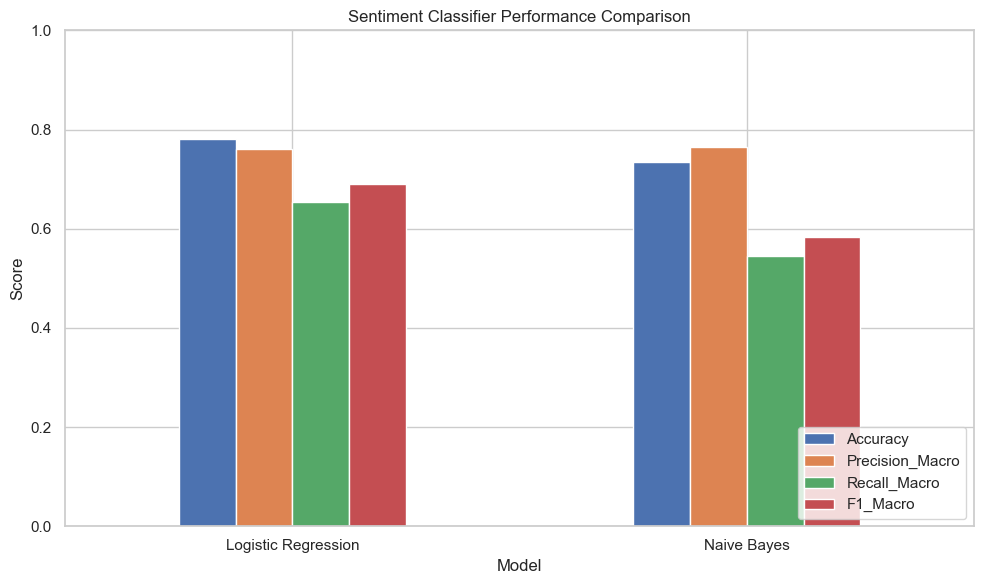

In [11]:
metrics_to_plot = [
    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro"
]

results_df[metrics_to_plot].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Sentiment Classifier Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "model_comparison.png",
    dpi=150
)
plt.show()

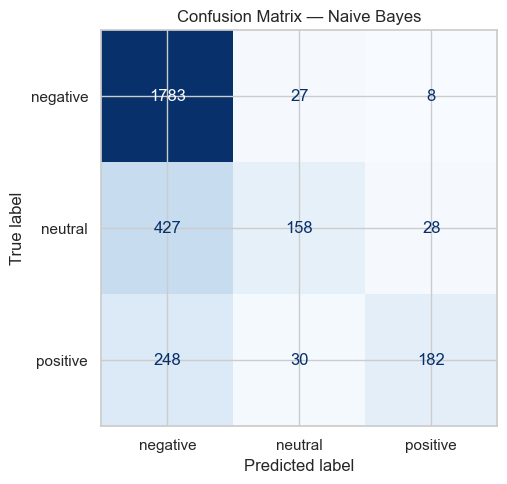

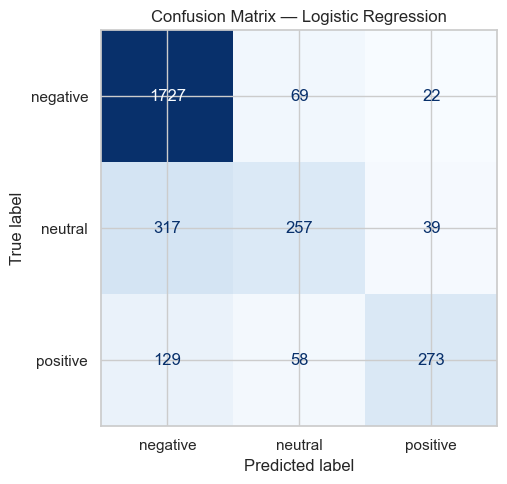

In [12]:
labels = ["negative", "neutral", "positive"]

for model_name, y_pred in predictions.items():
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=labels
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    )

    fig, ax = plt.subplots(figsize=(7, 5))
    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"Confusion Matrix — {model_name}")
    plt.tight_layout()

    safe_name = model_name.lower().replace(" ", "_")
    plt.savefig(
        OUTPUT_DIR / f"confusion_matrix_{safe_name}.png",
        dpi=150
    )

    plt.show()

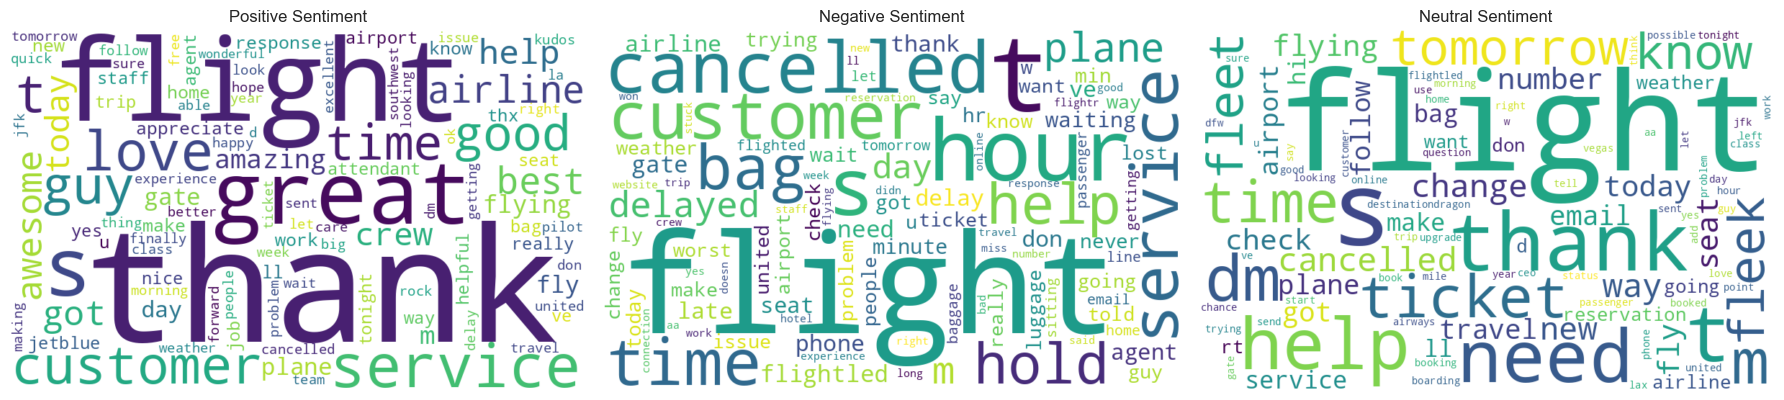

In [13]:
sentiments = ["positive", "negative", "neutral"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, sentiment in zip(axes, sentiments):
    class_text = " ".join(
        df.loc[
            df["airline_sentiment"] == sentiment,
            "clean_text"
        ].tolist()
    )

    ax.set_title(f"{sentiment.title()} Sentiment")

    if class_text.strip():
        cloud = WordCloud(
            width=800,
            height=500,
            background_color="white",
            collocations=False,
            max_words=100,
            random_state=RANDOM_STATE
        ).generate(class_text)

        ax.imshow(cloud, interpolation="bilinear")
    else:
        ax.text(0.5, 0.5, "No text available", ha="center", va="center")

    ax.axis("off")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "sentiment_wordclouds.png",
    dpi=150
)
plt.show()

In [14]:
best_model_name = results_df.index[0]
best_model = models[best_model_name]
best_predictions = predictions[best_model_name]

error_df = pd.DataFrame({
    "Original_Text": df.loc[X_test.index, "text"].values,
    "Cleaned_Text": X_test.values,
    "Actual_Sentiment": y_test.values,
    "Predicted_Sentiment": best_predictions
}, index=X_test.index)

misclassified = error_df[
    error_df["Actual_Sentiment"] !=
    error_df["Predicted_Sentiment"]
].copy()

print("Best model by macro F1:", best_model_name)
print("Number of misclassified test examples:", len(misclassified))

five_errors = misclassified.head(5)

display(five_errors[
    [
        "Original_Text",
        "Actual_Sentiment",
        "Predicted_Sentiment"
    ]
])

five_errors.to_csv(
    OUTPUT_DIR / "five_misclassified_examples.csv",
    index=False
)

Best model by macro F1: Logistic Regression
Number of misclassified test examples: 634


,Original_Text,Actual_Sentiment,Predicted_Sentiment
5509,@SouthwestAir OMG OMG OMG !!! I JUST DID!!,neutral,negative
5510,@SouthwestAir @JulGood1 she was traveling with...,negative,neutral
8215,@JetBlue Although it wasn't totally the answer...,positive,negative
8606,@JetBlue Just a thought!,neutral,negative
12276,@AmericanAir that's what is on my ticket and m...,neutral,negative


In [15]:
def investigate_error(row):
    text = str(row["Original_Text"]).lower()
    actual = row["Actual_Sentiment"]
    predicted = row["Predicted_Sentiment"]

    if any(word in text for word in ["not ", "never ", "no "]):
        return "Possible negation or phrase-context issue"

    if any(word in text for word in ["but", "although", "however"]):
        return "Mixed or contrasting sentiment"

    if "?" in text:
        return "Question or request may have ambiguous sentiment"

    if any(word in text for word in [":)", ":-)", "<3"]):
        return "Emoji or informal expression may affect interpretation"

    return (
        f"Inspect context: true={actual}, predicted={predicted}; "
        "possible ambiguity, limited context, or label noise"
    )

five_errors = five_errors.copy()
five_errors["Investigation_Note"] = five_errors.apply(
    investigate_error,
    axis=1
)

display(five_errors[
    [
        "Original_Text",
        "Actual_Sentiment",
        "Predicted_Sentiment",
        "Investigation_Note"
    ]
])

,Original_Text,Actual_Sentiment,Predicted_Sentiment,Investigation_Note
5509,@SouthwestAir OMG OMG OMG !!! I JUST DID!!,neutral,negative,"Inspect context: true=neutral, predicted=negat..."
5510,@SouthwestAir @JulGood1 she was traveling with...,negative,neutral,"Inspect context: true=negative, predicted=neut..."
8215,@JetBlue Although it wasn't totally the answer...,positive,negative,Mixed or contrasting sentiment
8606,@JetBlue Just a thought!,neutral,negative,"Inspect context: true=neutral, predicted=negat..."
12276,@AmericanAir that's what is on my ticket and m...,neutral,negative,Question or request may have ambiguous sentiment


In [16]:
def predict_sentiment(text):
    cleaned_text = preprocess_text(text)

    prediction = best_model.predict([cleaned_text])[0]

    return {
        "Input_Text": text,
        "Cleaned_Text": cleaned_text,
        "Predicted_Sentiment": prediction
    }


examples = [
    "The flight attendants were amazing and very helpful!",
    "My flight was delayed again and customer service was terrible.",
    "Can someone tell me the departure time for my flight?"
]

for example in examples:
    print(predict_sentiment(example))

{'Input_Text': 'The flight attendants were amazing and very helpful!', 'Cleaned_Text': 'flight attendants amazing helpful', 'Predicted_Sentiment': 'positive'}
{'Input_Text': 'My flight was delayed again and customer service was terrible.', 'Cleaned_Text': 'flight delayed customer service terrible', 'Predicted_Sentiment': 'negative'}
{'Input_Text': 'Can someone tell me the departure time for my flight?', 'Cleaned_Text': 'tell departure time flight', 'Predicted_Sentiment': 'negative'}


In [17]:
import joblib

model_path = OUTPUT_DIR / "sentiment_model.joblib"

joblib.dump(best_model, model_path)

print("Model saved to:", model_path)

Model saved to: output\sentiment_model.joblib


In [18]:
loaded_model = joblib.load(
    "output/sentiment_model.joblib"
)

sample_text = "The service was excellent!"
cleaned = preprocess_text(sample_text)

print("Predicted sentiment:", loaded_model.predict([cleaned])[0])

Predicted sentiment: positive
